In [1]:

# Import necessary libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
df = pd.read_csv("/content/train.csv")

In [3]:
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [4]:
df.tail()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129
10885,2012-12-19 23:00:00,4,0,1,1,13.12,16.665,66,8.9981,4,84,88


In [5]:
df.shape[0]

10886

In [6]:
df.shape[1]

12

In [7]:
print(df.columns)

Index(['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count'],
      dtype='object')


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [9]:
df.describe()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


In [10]:
print("Dataset Size:", df.size)

Dataset Size: 130632


In [11]:
df.isnull().sum()

,0
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:

# Select numerical columns for outlier detection

columns = ['temp', 'atemp', 'humidity',
           'windspeed', 'count']

# Calculate outliers using IQR

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")


temp: 0 outliers
atemp: 0 outliers
humidity: 22 outliers
windspeed: 227 outliers
count: 300 outliers


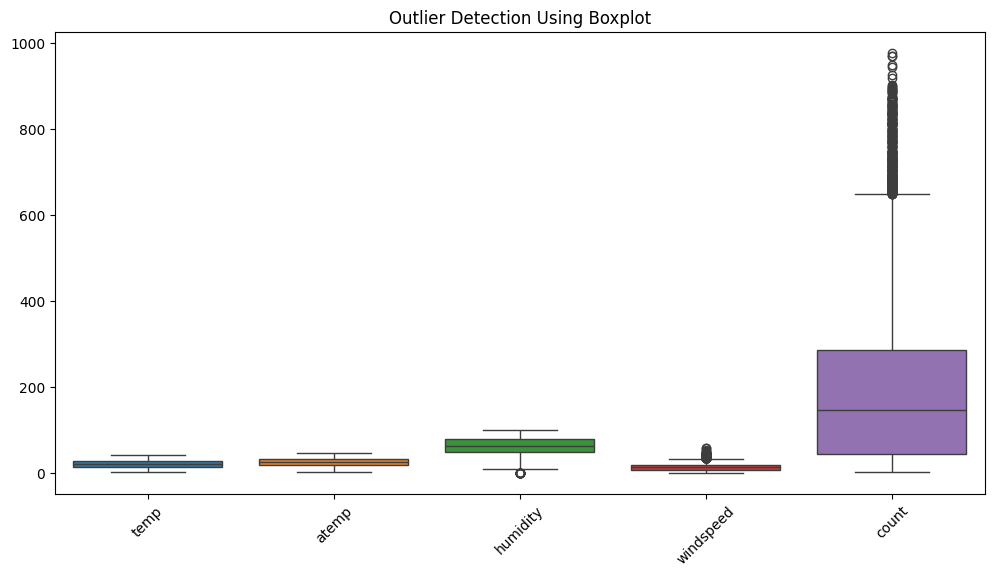

In [14]:

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[columns])

plt.title("Outlier Detection Using Boxplot")
plt.xticks(rotation=45)
plt.show()


In [15]:
df_clean = df.copy()

print("Clean dataset created successfully!")
print("Shape:", df_clean.shape)

Clean dataset created successfully!
Shape: (10886, 12)


In [16]:

# Convert datetime column

df_clean['datetime'] = pd.to_datetime(
    df_clean['datetime'],
    errors='coerce'
)

print(df_clean['datetime'].dtype)


datetime64[ns]


In [17]:

# Verify missing values after cleaning

print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())


Missing values after cleaning:
0


In [18]:

# Check total rental count

check = (
    df_clean['casual'] + df_clean['registered']
    == df_clean['count']
)

print("All rental counts are correct:", check.all())


All rental counts are correct: True


In [19]:

# Display cleaned data

df_clean.head()


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [20]:
df_clean.describe()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2011-12-27 05:56:22.399411968,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
min,2011-01-01 00:00:00,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2011-07-02 07:15:00,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,2012-01-01 20:30:00,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,2012-07-01 12:45:00,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,2012-12-19 23:00:00,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000
std,NaN,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454


In [21]:
# Average bike rentals by season

season_analysis = df_clean.groupby('season')['count'].mean()

print(season_analysis)

season
1    116.343261
2    215.251372
3    234.417124
4    198.988296
Name: count, dtype: float64


In [22]:
# Average bike rentals by weather

weather_analysis = df_clean.groupby('weather')['count'].mean()

print(weather_analysis)

weather
1    205.236791
2    178.955540
3    118.846333
4    164.000000
Name: count, dtype: float64


In [23]:
# Compare working days and non-working days

workingday_analysis = df_clean.groupby('workingday')['count'].mean()

print(workingday_analysis)

workingday
0    188.506621
1    193.011873
Name: count, dtype: float64


In [24]:
# Extract hour from datetime

df_clean['hour'] = df_clean['datetime'].dt.hour

# Average rentals for each hour

hour_analysis = df_clean.groupby('hour')['count'].mean()

print(hour_analysis)

hour
0      55.138462
1      33.859031
2      22.899554
3      11.757506
4       6.407240
5      19.767699
6      76.259341
7     213.116484
8     362.769231
9     221.780220
10    175.092308
11    210.674725
12    256.508772
13    257.787281
14    243.442982
15    254.298246
16    316.372807
17    468.765351
18    430.859649
19    315.278509
20    228.517544
21    173.370614
22    133.576754
23     89.508772
Name: count, dtype: float64


In [25]:
# Calculate correlation

print("Temperature and Bike Rental Correlation:")

print(df_clean['temp'].corr(df_clean['count']))

Temperature and Bike Rental Correlation:
0.394453644967249


In [26]:
print("Humidity and Bike Rental Correlation:")

print(df_clean['humidity'].corr(df_clean['count']))

Humidity and Bike Rental Correlation:
-0.31737147887659456


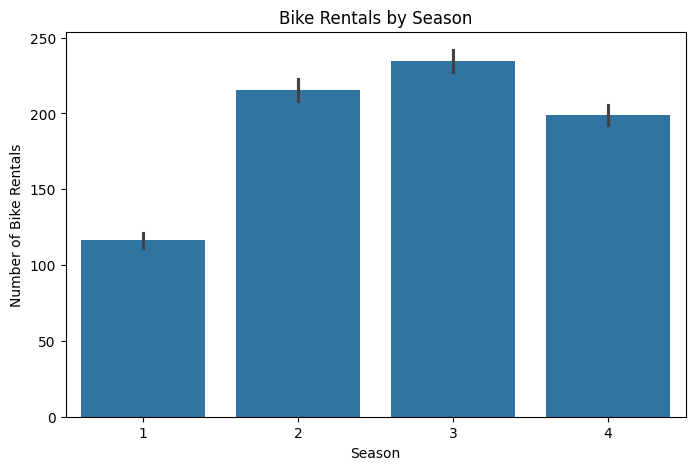

In [27]:
plt.figure(figsize=(8,5))

sns.barplot(x='season', y='count', data=df_clean)

plt.title("Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Number of Bike Rentals")

plt.show()

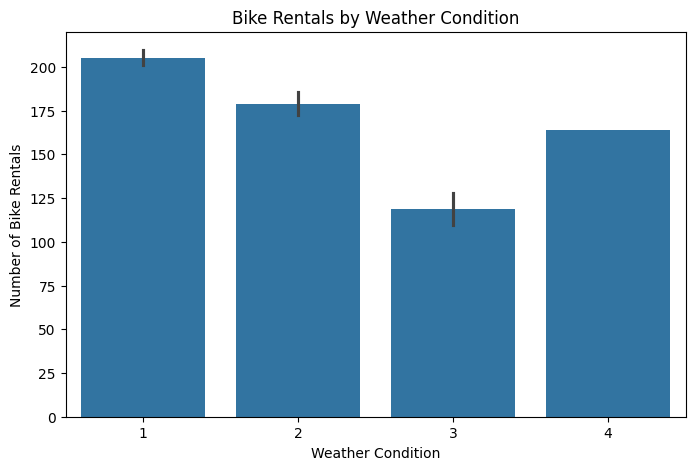

In [28]:
plt.figure(figsize=(8,5))

sns.barplot(x='weather', y='count', data=df_clean)

plt.title("Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Bike Rentals")

plt.show()

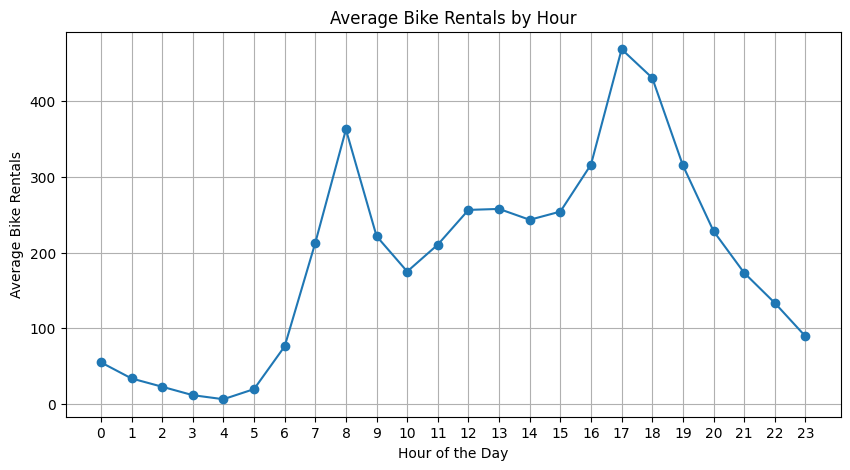

In [29]:
hourly_data = df_clean.groupby('hour')['count'].mean()

plt.figure(figsize=(10,5))

plt.plot(hourly_data.index, hourly_data.values,
         marker='o')

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Bike Rentals")

plt.xticks(range(0,24))
plt.grid()
plt.show()

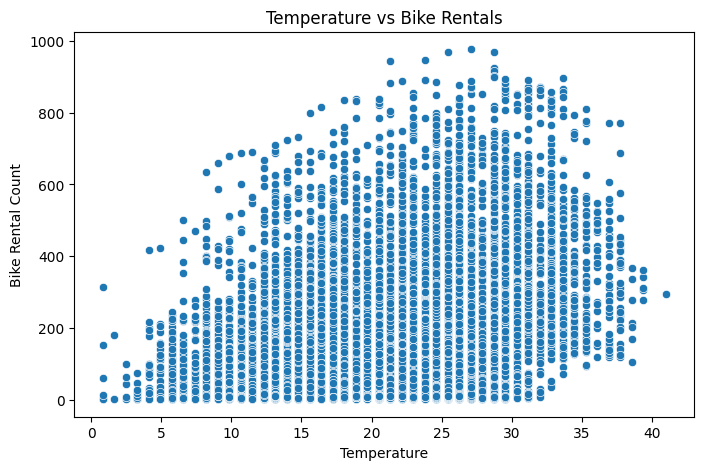

In [30]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='temp', y='count', data=df_clean)

plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Bike Rental Count")

plt.show()

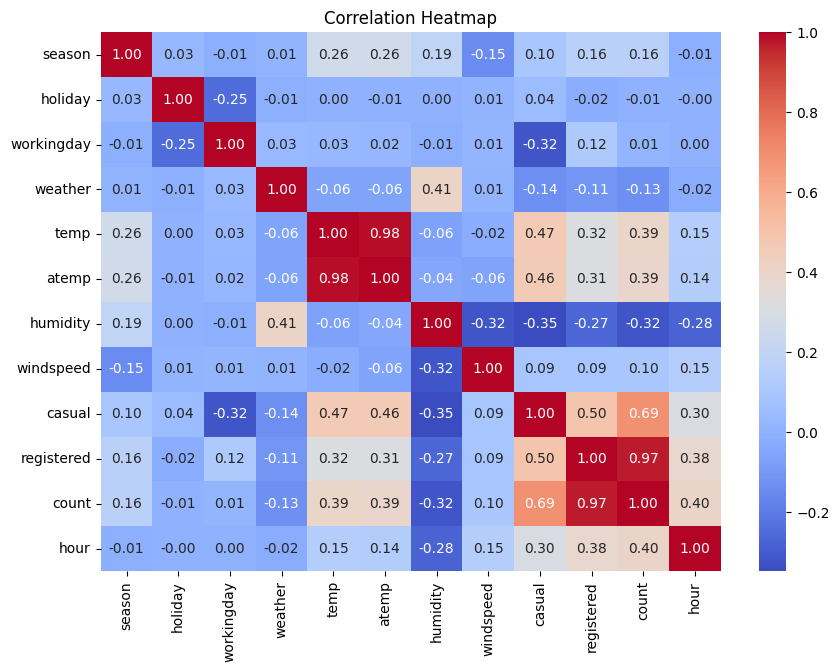

In [31]:
plt.figure(figsize=(10,7))

corr = df_clean.select_dtypes(
    include='number'
).corr()

sns.heatmap(corr, annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

In [32]:
# Extract useful features from datetime

df_clean['hour'] = df_clean['datetime'].dt.hour
df_clean['dayofweek'] = df_clean['datetime'].dt.dayofweek
df_clean['month'] = df_clean['datetime'].dt.month
df_clean['year'] = df_clean['datetime'].dt.year

print("Date and time features extracted successfully!")

df_clean[['datetime', 'hour', 'dayofweek',
          'month', 'year']].head()

Date and time features extracted successfully!


,datetime,hour,dayofweek,month,year
0,2011-01-01 00:00:00,0,5,1,2011
1,2011-01-01 01:00:00,1,5,1,2011
2,2011-01-01 02:00:00,2,5,1,2011
3,2011-01-01 03:00:00,3,5,1,2011
4,2011-01-01 04:00:00,4,5,1,2011


In [33]:
# Separate input features and target

X = df_clean.drop(
    columns=['datetime', 'casual',
             'registered', 'count']
)

y = df_clean['count']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (10886, 12)
Target Shape: (10886,)


In [34]:
# Apply One-Hot Encoding

X = pd.get_dummies(
    X,
    columns=['season', 'weather', 'hour',
             'dayofweek', 'month', 'year'],
    dtype=int
)

print("Categorical Encoding Completed!")

Categorical Encoding Completed!


In [35]:
# Display final feature dataset

X.head()

,holiday,workingday,temp,atemp,humidity,windspeed,season_1,season_2,season_3,season_4,...,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2011,year_2012
0,0,0,9.84,14.395,81,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0,0,9.02,13.635,80,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,9.02,13.635,80,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,0,0,9.84,14.395,75,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0,0,9.84,14.395,75,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [36]:
# Check data types

X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 59 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   holiday      10886 non-null  int64  
 1   workingday   10886 non-null  int64  
 2   temp         10886 non-null  float64
 3   atemp        10886 non-null  float64
 4   humidity     10886 non-null  int64  
 5   windspeed    10886 non-null  float64
 6   season_1     10886 non-null  int64  
 7   season_2     10886 non-null  int64  
 8   season_3     10886 non-null  int64  
 9   season_4     10886 non-null  int64  
 10  weather_1    10886 non-null  int64  
 11  weather_2    10886 non-null  int64  
 12  weather_3    10886 non-null  int64  
 13  weather_4    10886 non-null  int64  
 14  hour_0       10886 non-null  int64  
 15  hour_1       10886 non-null  int64  
 16  hour_2       10886 non-null  int64  
 17  hour_3       10886 non-null  int64  
 18  hour_4       10886 non-null  int64  
 19  hour

In [37]:
# Check target variable

y.head()

,count
0,16
1,40
2,32
3,13
4,1


In [40]:
X.isnull().sum().sum()
y.isnull().sum()

np.int64(0)

In [41]:

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Data Shape: (8708, 59)
Testing Data Shape: (2178, 59)
Training Target Shape: (8708,)
Testing Target Shape: (2178,)


In [42]:

# Create Linear Regression model

model = LinearRegression()

print("Linear Regression Model Created Successfully!")


Linear Regression Model Created Successfully!


In [43]:

# Train the model using training data

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")


Model Training Completed Successfully!


In [44]:

# Predict bike rental demand

y_pred = model.predict(X_test)

print("Predictions Generated Successfully!")

print("First 10 Predictions:")
print(y_pred[:10])


Predictions Generated Successfully!
First 10 Predictions:
[229.35979293  15.96732336 349.40098222 258.00292286 203.27497466
 236.36950873 159.61676802 243.61273011 393.53767045  14.59310242]


In [45]:

# Compare actual and predicted values

comparison = pd.DataFrame({
    'Actual Count': y_test.values,
    'Predicted Count': y_pred
})

comparison.head(10)


,Actual Count,Predicted Count
0,127,229.359793
1,13,15.967323
2,163,349.400982
3,233,258.002923
4,222,203.274975
5,166,236.369509
6,144,159.616768
7,376,243.612730
8,601,393.537670
9,53,14.593102


In [46]:

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)


Mean Absolute Error: 74.11090488303971


In [47]:

mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)


Mean Squared Error: 10027.066125062089


In [48]:

rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)


Root Mean Squared Error: 100.13523917713528


In [49]:

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)


R2 Score: 0.6962133605475473


In [50]:

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MODEL EVALUATION RESULTS
------------------------
MAE: 74.11090488303971
MSE: 10027.066125062089
RMSE: 100.13523917713528
R2 Score: 0.6962133605475473
